# 04 — Trading activity and the final 54-product universe

The requested window is **2016–2021**; observed data cover **4 January 2016–18 October 2021**, **1,407 trading dates** and **77 files**.

The authoritative universe contains **54 files**: activity **≥30%**, zero-volume minutes **≤38%**, and problematic key-field bars **≤0.1%**. All 54 eligible products are retained and ordered by mean daily monetary turnover. Daily volume, closing open interest and zero/problematic-bar shares remain separate diagnostics.

The zero-volume limit was increased from 30% to 38% to obtain the requested universe size; 30% admits only 52 candidates. Relative to the earlier 50-product set, **B, CY, NR and RR** are added.

The earlier activity-only comparison (**80% →42 files**, **43% →54 files**) is retained for context. The final section defines the authoritative `final_selected_assets` and `final_universe`. Selection uses the complete observed window and is retrospective.


## Definition and methodology

Observed trading frequency is a liquidity proxy:

$$A_i=\frac{\#\{d\in D:\sum_{t\in d}Volume_{i,t}>0\}}{|D|}\times100\%.$$

Here `i` is a source file (`instrument`), not an individual delivery `symbol`. Every file shares the same observed trading-date denominator, including short histories.

1. The source ends on 18 October 2021; the missing remainder of 2021 is outside the denominator.
2. Dates with daytime bars (`06:00≤hour<18:00`) in at least one file define an empirical data calendar, rather than an official exchange calendar.
3. Evening bars (`hour≥18`) map to the next calendar trading date. After-midnight bars (`hour<6`) map to the first calendar trading date on or after their date. Vendor local timestamps are used; Saturday night-session bars do not create an extra trading day.
4. A date with no records is not counted as an observed positive-volume date. This describes coverage and activity; it does not assert that true market volume was zero. Files without observations are identified separately.
5. Missing volumes are not filled. With nonnegative known volumes, one positive bar establishes activity; incomplete dates without a positive bar require investigation.
6. The historical 43% threshold was chosen on this sample to admit 54 files. It is a universe-size rule, rather than an independently established liquidity standard. Spread, depth and market impact are unobserved.

Earlier research also used volume, `money`/turnover, open interest, log activity and zero-volume-minute shares. This notebook's activity measure is specifically the daily frequency above.


## Data and parameters

Input: `artifacts/clean_market_data.parquet` from notebook 01; file membership and checksum: `artifacts/data_manifest.json`. A previous summary CSV is used only for reconciliation when available.

Run from the repository root with Python 3.11+, NumPy, pandas, PyArrow, Matplotlib and IPython. DuckDB and the other research notebooks are unnecessary when the cleaned Parquet already exists.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import platform
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display, Markdown, HTML

ROOT = Path.cwd()
SOURCE = ROOT / "artifacts/clean_market_data.parquet"
MANIFEST = ROOT / "artifacts/data_manifest.json"
OUTPUT_DIR = ROOT / "artifacts/research/liquidity_activity"
FIGURE_DIR = OUTPUT_DIR / "figures"
WINDOW_START = pd.Timestamp("2016-01-01")
WINDOW_END_EXCLUSIVE = pd.Timestamp("2022-01-01")
# Buffer for night sessions preceding the requested window.
READ_START = WINDOW_START - pd.Timedelta(days=31)
BASELINE_THRESHOLD_PCT = 80
SELECTED_THRESHOLD_PCT = 43
TARGET_FILES = 54

if not SOURCE.exists() or not MANIFEST.exists():
    raise FileNotFoundError("Open the notebook from the repository root; clean_market_data.parquet and data_manifest.json are required.")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {"pass": "#285B7E", "fail": "#AEB8C2", "threshold": "#B56721", "reference": "#59636F"}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#25313D",
    "text.color": "#25313D", "axes.edgecolor": "#AEB8C2",
    "savefig.facecolor": "white", "figure.facecolor": "white",
})

def show_table(frame, formats=None, scroll=False):
    styled = frame.style.hide(axis="index").format(formats or {}, na_rep="—")
    styled = styled.set_properties(**{"padding": "6px 10px", "text-align": "left"})
    if scroll:
        display(HTML('<div style="max-height:650px;overflow:auto">' + styled.to_html() + '</div>'))
    else:
        display(styled)

### 1. Verify the source and load required fields


In [2]:
manifest = json.loads(MANIFEST.read_text())
universe = pd.Index(sorted(item["instrument"] for item in manifest["raw_files"]), name="instrument")
assert universe.is_unique and len(universe) == manifest["instrument_count"]
with SOURCE.open("rb") as stream:
    source_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()
assert source_sha256 == manifest["output_sha256"], "Source checksum differs from the saved manifest."

dataset = ds.dataset(SOURCE, format="parquet")
assert {"instrument", "date", "volume"}.issubset(dataset.schema.names)
scan_filter = ((ds.field("date") >= READ_START.to_pydatetime()) &
               (ds.field("date") < WINDOW_END_EXCLUSIVE.to_pydatetime()))
parts = []
source_preview = None
negative_volume_bars = 0
source_first_timestamp = None
source_last_timestamp = None
for batch in dataset.to_batches(columns=["instrument", "date", "volume"],
                                filter=scan_filter, batch_size=500_000):
    frame = batch.to_pandas()
    if frame.empty:
        continue
    if source_preview is None:
        source_preview = frame.loc[frame.date.ge(WINDOW_START)].head(5).copy()
    source_first_timestamp = min(source_first_timestamp, frame.date.min()) if source_first_timestamp is not None else frame.date.min()
    source_last_timestamp = max(source_last_timestamp, frame.date.max()) if source_last_timestamp is not None else frame.date.max()
    finite = np.isfinite(frame.volume.to_numpy())
    negative_volume_bars += int((finite & frame.volume.lt(0).to_numpy()).sum())
    hour = frame.date.dt.hour
    frame["calendar_day"] = frame.date.dt.normalize()
    frame["session"] = np.select([hour.lt(6), hour.ge(18)], ["early", "evening"], default="daytime")
    frame["known_volume_bars"] = finite.astype("int64")
    frame["positive_bars"] = (finite & frame.volume.gt(0).to_numpy()).astype("int64")
    # Zeros are used only in partial sums; unknown counts remain separate.
    frame["known_volume_sum"] = frame.volume.where(finite, 0.0)
    part = frame.groupby(["instrument", "calendar_day", "session"], as_index=False, observed=True).agg(
        known_volume_sum=("known_volume_sum", "sum"), bars=("volume", "size"),
        known_volume_bars=("known_volume_bars", "sum"), positive_bars=("positive_bars", "sum"))
    parts.append(part)
assert parts, "The requested window has no observations."
assert negative_volume_bars == 0, "Negative volumes require an explicit treatment rule."
sessions = pd.concat(parts, ignore_index=True).groupby(
    ["instrument", "calendar_day", "session"], as_index=False, observed=True
)[["known_volume_sum", "bars", "known_volume_bars", "positive_bars"]].sum()
del parts, frame, batch
print(f"Source files: {len(universe)}. SHA-256 matches the manifest.")
print(f"Last source timestamp in the selected data: {source_last_timestamp}.")
display(source_preview)

Source files: 77. SHA-256 matches the manifest.
Last source timestamp in the selected data: 2021-10-18 15:15:00.


,instrument,date,volume
8475,A9999.XDCE.csv,2016-01-04 09:01:00,1170.0
8476,A9999.XDCE.csv,2016-01-04 09:02:00,1980.0
8477,A9999.XDCE.csv,2016-01-04 09:03:00,1564.0
8478,A9999.XDCE.csv,2016-01-04 09:04:00,4844.0
8479,A9999.XDCE.csv,2016-01-04 09:05:00,724.0


### 2. Trading calendar and daily volume


In [3]:
calendar = pd.DatetimeIndex(sessions.loc[sessions.session.eq("daytime"), "calendar_day"].unique()).sort_values()
indices = calendar.searchsorted(sessions.calendar_day, side="left")
evening = sessions.session.eq("evening")
indices[evening.to_numpy()] = calendar.searchsorted(sessions.loc[evening, "calendar_day"], side="right")
assert (indices < len(calendar)).all(), "Night sessions lack a subsequent observed trading date."
sessions["trading_day"] = calendar.take(indices).to_numpy()
window_calendar = calendar[(calendar >= WINDOW_START) & (calendar < WINDOW_END_EXCLUSIVE)]
window_sessions = sessions.loc[sessions.trading_day.isin(window_calendar)].copy()
daily = window_sessions.groupby(["instrument", "trading_day"], as_index=False).agg(
    known_volume_sum=("known_volume_sum", "sum"), bars=("bars", "sum"),
    known_volume_bars=("known_volume_bars", "sum"), positive_bars=("positive_bars", "sum"))
daily["daily_volume"] = daily.known_volume_sum.where(daily.known_volume_bars.gt(0))
daily["active"] = daily.daily_volume.gt(0)
daily["unknown_volume_bars"] = daily.bars - daily.known_volume_bars
daily["uncertain_activity"] = daily.unknown_volume_bars.gt(0) & ~daily.active
assert not daily.duplicated(["instrument", "trading_day"]).any()
assert not daily.uncertain_activity.any(), "Incomplete dates without positive volume require investigation."
assert daily.active.eq(daily.positive_bars.gt(0)).all()
window_days = len(window_calendar)
calendar_table = pd.DataFrame({"trading_day": window_calendar})
calendar_by_year = calendar_table.groupby(calendar_table.trading_day.dt.year).size().rename("Trading dates").reset_index()
calendar_by_year.columns = ["Year", "Trading dates"]
show_table(calendar_by_year)
print(f"Total: {window_days:,} trading dates; unknown minute volumes: {daily.unknown_volume_bars.sum():,}.")

Year,Trading dates
2016,244
2017,244
2018,243
2019,244
2020,243
2021,189


Total: 1,407 trading dates; unknown minute volumes: 25.


### 3. File activity and selection thresholds


In [4]:
activity = daily.groupby("instrument").agg(
    observed_days=("trading_day", "size"), positive_volume_days=("active", "sum"),
    first_day=("trading_day", "min"), last_day=("trading_day", "max"),
    unknown_volume_bars=("unknown_volume_bars", "sum"),
    uncertain_activity_days=("uncertain_activity", "sum"))
activity = activity.reindex(universe)
count_columns = ["observed_days", "positive_volume_days", "unknown_volume_bars", "uncertain_activity_days"]
activity[count_columns] = activity[count_columns].fillna(0).astype("int64")
activity["window_trading_days"] = window_days
activity["missing_days"] = window_days - activity.observed_days
activity["activity_pct"] = 100 * activity.positive_volume_days / window_days
activity["own_days_activity_pct"] = 100 * activity.positive_volume_days / activity.observed_days.replace(0, np.nan)
activity["passes_80pct"] = activity.positive_volume_days * 100 >= BASELINE_THRESHOLD_PCT * window_days
activity["passes_43pct"] = activity.positive_volume_days * 100 >= SELECTED_THRESHOLD_PCT * window_days
activity["has_observations"] = activity.observed_days.gt(0)
activity = activity.reset_index().sort_values(["positive_volume_days", "instrument"], ascending=[False, True]).reset_index(drop=True)
activity.insert(0, "rank", np.arange(1, len(activity) + 1))
assert activity.positive_volume_days.le(activity.observed_days).all()
assert activity.observed_days.le(window_days).all()
assert activity.activity_pct.between(0, 100).all()

threshold_results = pd.DataFrame([
    {"Threshold, %": threshold, "Minimum active dates": math.ceil(threshold * window_days / 100),
     "Passing files": int((activity.positive_volume_days * 100 >= threshold * window_days).sum())}
    for threshold in [BASELINE_THRESHOLD_PCT, SELECTED_THRESHOLD_PCT]
])
show_table(threshold_results)

"Threshold, %",Minimum active dates,Passing files
80,1126,42
43,606,54


## Results

### 4. Why 43% admits exactly 54 files

For `A_i≥t`, exactly 54 files pass when the threshold is strictly above the 55th file's activity and no greater than the 54th file's activity. Exact numerators and the common denominator determine selection; rounded percentages are display values only.


In [5]:
last_selected = activity.iloc[TARGET_FILES - 1]
first_rejected = activity.iloc[TARGET_FILES]
lower_exclusive = float(first_rejected.activity_pct)
upper_inclusive = float(last_selected.activity_pct)
assert lower_exclusive < upper_inclusive, "Tied activity at the boundary: a single threshold cannot separate the files."
assert lower_exclusive < SELECTED_THRESHOLD_PCT <= upper_inclusive
assert int(activity.passes_43pct.sum()) == TARGET_FILES
boundary = activity.loc[activity["rank"].between(TARGET_FILES - 3, TARGET_FILES + 3),
                        ["rank", "instrument", "positive_volume_days", "activity_pct", "passes_43pct"]].copy()
boundary.columns = ["Rank", "File", "Active dates", "Activity, %", "Passes 43%"]
boundary["Passes 43%"] = boundary["Passes 43%"].map({True: "Yes", False: "No"})
show_table(boundary, {"Activity, %": "{:.4f}"})
display(Markdown(
    f"**Admissible threshold interval:** ({lower_exclusive:.8f}%; {upper_inclusive:.8f}%]. "
    f"Selected **{SELECTED_THRESHOLD_PCT}%**: **{int(activity.passes_43pct.sum())}/{len(activity)} files** pass."
))

Rank,File,Active dates,"Activity, %",Passes 43%
51,EG9999.XDCE.csv,691,49.1116,Yes
52,JR9999.XZCE.csv,688,48.8984,Yes
53,WR9999.XSGE.csv,651,46.2687,Yes
54,RI9999.XZCE.csv,611,43.4257,Yes
55,CJ9999.XZCE.csv,598,42.5018,No
56,UR9999.XZCE.csv,529,37.5977,No
57,NR9999.XINE.csv,528,37.5267,No


**Admissible threshold interval:** (42.50177683%; 43.42572850%]. Selected **43%**: **54/77 files** pass.

### 5. Activity distribution

Each observation is one source file. Histogram bins have a width of five percentage points; the final bin includes 100%. Six files without observations have a zero numerator under the common-window definition and enter the first bin. Selection uses original values, rather than histogram bins.


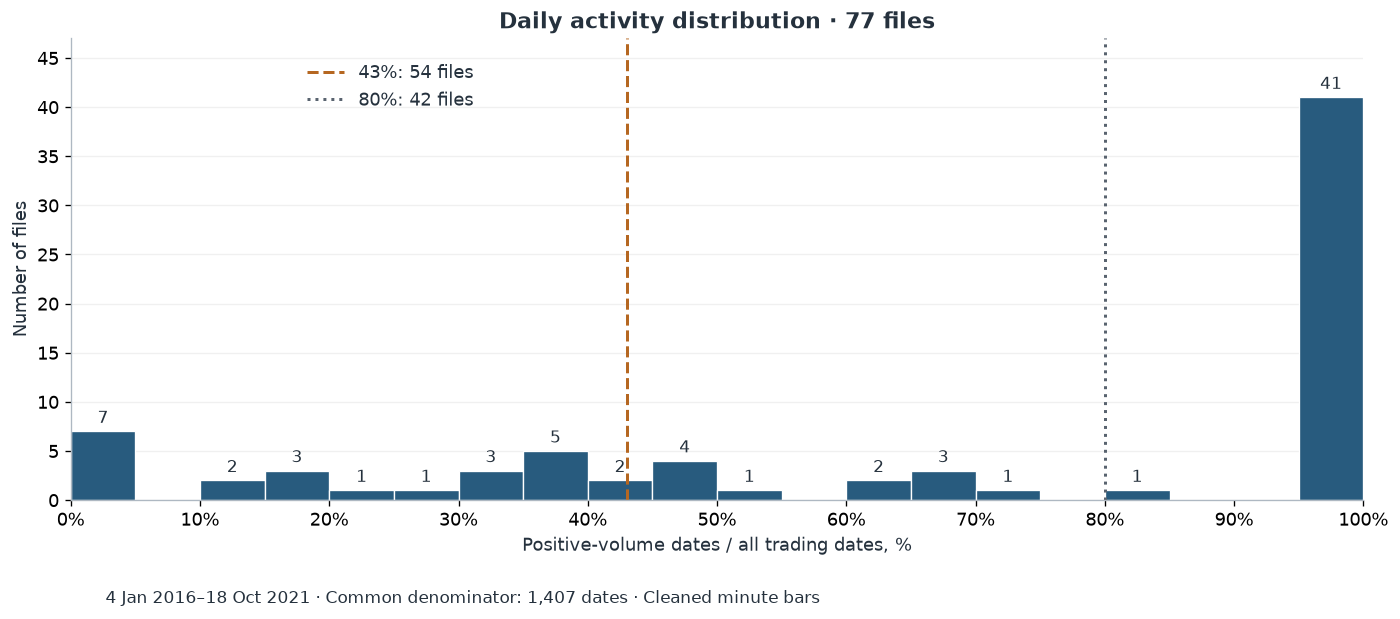

In [6]:
fig, ax = plt.subplots(figsize=(11.8, 5.2))
counts, edges, patches = ax.hist(activity.activity_pct, bins=np.arange(0, 105, 5),
                                 color=COLORS["pass"], edgecolor="white", linewidth=0.8)
for count, left, right in zip(counts, edges[:-1], edges[1:]):
    if count:
        ax.text((left + right) / 2, count + 0.45, str(int(count)), ha="center", va="bottom", fontsize=10)
ax.axvline(SELECTED_THRESHOLD_PCT, color=COLORS["threshold"], linestyle="--", linewidth=1.8,
           label=f"43%: {int(activity.passes_43pct.sum())} files")
ax.axvline(BASELINE_THRESHOLD_PCT, color=COLORS["reference"], linestyle=":", linewidth=1.8,
           label=f"80%: {int(activity.passes_80pct.sum())} files")
ax.set(xlim=(0, 100), ylim=(0, max(counts) + 6), xlabel="Positive-volume dates / all trading dates, %",
       ylabel="Number of files", title="Daily activity distribution · 77 files")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_xticks(np.arange(0, 101, 10))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.18); ax.set_axisbelow(True)
ax.legend(loc="upper left", bbox_to_anchor=(0.17, 0.98), frameon=False)
fig.text(0.08, 0.02, f"4 Jan 2016–18 Oct 2021 · Common denominator: {window_days:,} dates · Cleaned minute bars", fontsize=10)
fig.tight_layout(rect=(0, 0.065, 1, 1))
fig.savefig(FIGURE_DIR / "activity_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

### 6. Activity by source file

Files are ordered by decreasing activity, then filename. Three panels share the same scale so all 77 labels remain readable. Blue bars pass 43%; grey bars fail. Dashed lines mark 43% and 80%. Files without records are explicitly labelled.


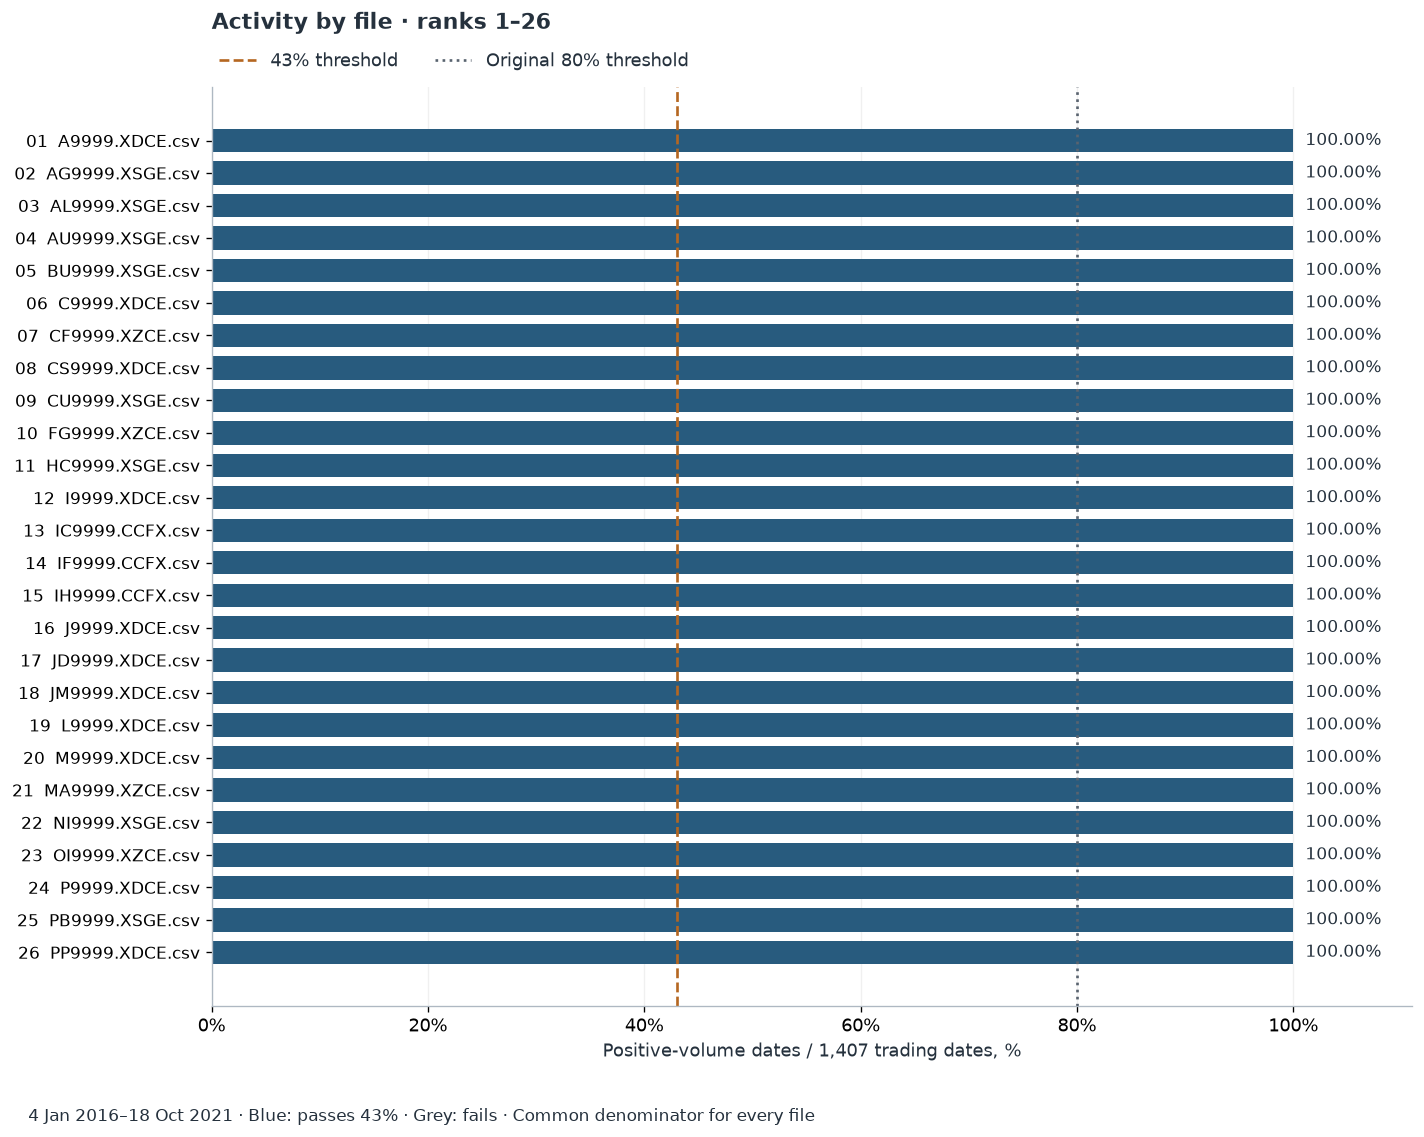

In [7]:
def plot_file_activity(start, stop, figure_name):
    group = activity.iloc[start:stop].copy()
    fig, ax = plt.subplots(figsize=(12, 9.6))
    positions = np.arange(len(group))
    bar_colors = np.where(group.passes_43pct, COLORS["pass"], COLORS["fail"])
    ax.barh(positions, group.activity_pct, color=bar_colors, height=0.72)
    labels = [f"{row.rank:02d}  {row.instrument}" for row in group.itertuples(index=False)]
    ax.set_yticks(positions, labels, fontsize=10)
    ax.invert_yaxis()
    for y, row in zip(positions, group.itertuples(index=False)):
        value_label = f"{row.activity_pct:.2f}%" if row.has_observations else "0.00% · no records"
        ax.text(row.activity_pct + 1.1, y, value_label, va="center", fontsize=10,
                zorder=5, bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.6})
    ax.axvline(SELECTED_THRESHOLD_PCT, color=COLORS["threshold"], linestyle="--", linewidth=1.6, label="43% threshold")
    ax.axvline(BASELINE_THRESHOLD_PCT, color=COLORS["reference"], linestyle=":", linewidth=1.6, label="Original 80% threshold")
    # Space above 100 is for labels; every data value remains in [0,100].
    ax.set_xlim(0, 111)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_xlabel(f"Positive-volume dates / {window_days:,} trading dates, %")
    ax.set_title(f"Activity by file · ranks {start + 1}–{min(stop, len(activity))}", loc="left", pad=35)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False, borderaxespad=0)
    ax.grid(axis="x", alpha=0.18); ax.set_axisbelow(True)
    fig.text(0.025, 0.02, "4 Jan 2016–18 Oct 2021 · Blue: passes 43% · Grey: fails · Common denominator for every file", fontsize=10)
    fig.tight_layout(rect=(0, 0.055, 1, 1))
    fig.savefig(FIGURE_DIR / figure_name, dpi=160, bbox_inches="tight")
    plt.show()

plot_file_activity(0, 26, "activity_by_file_01_26.png")

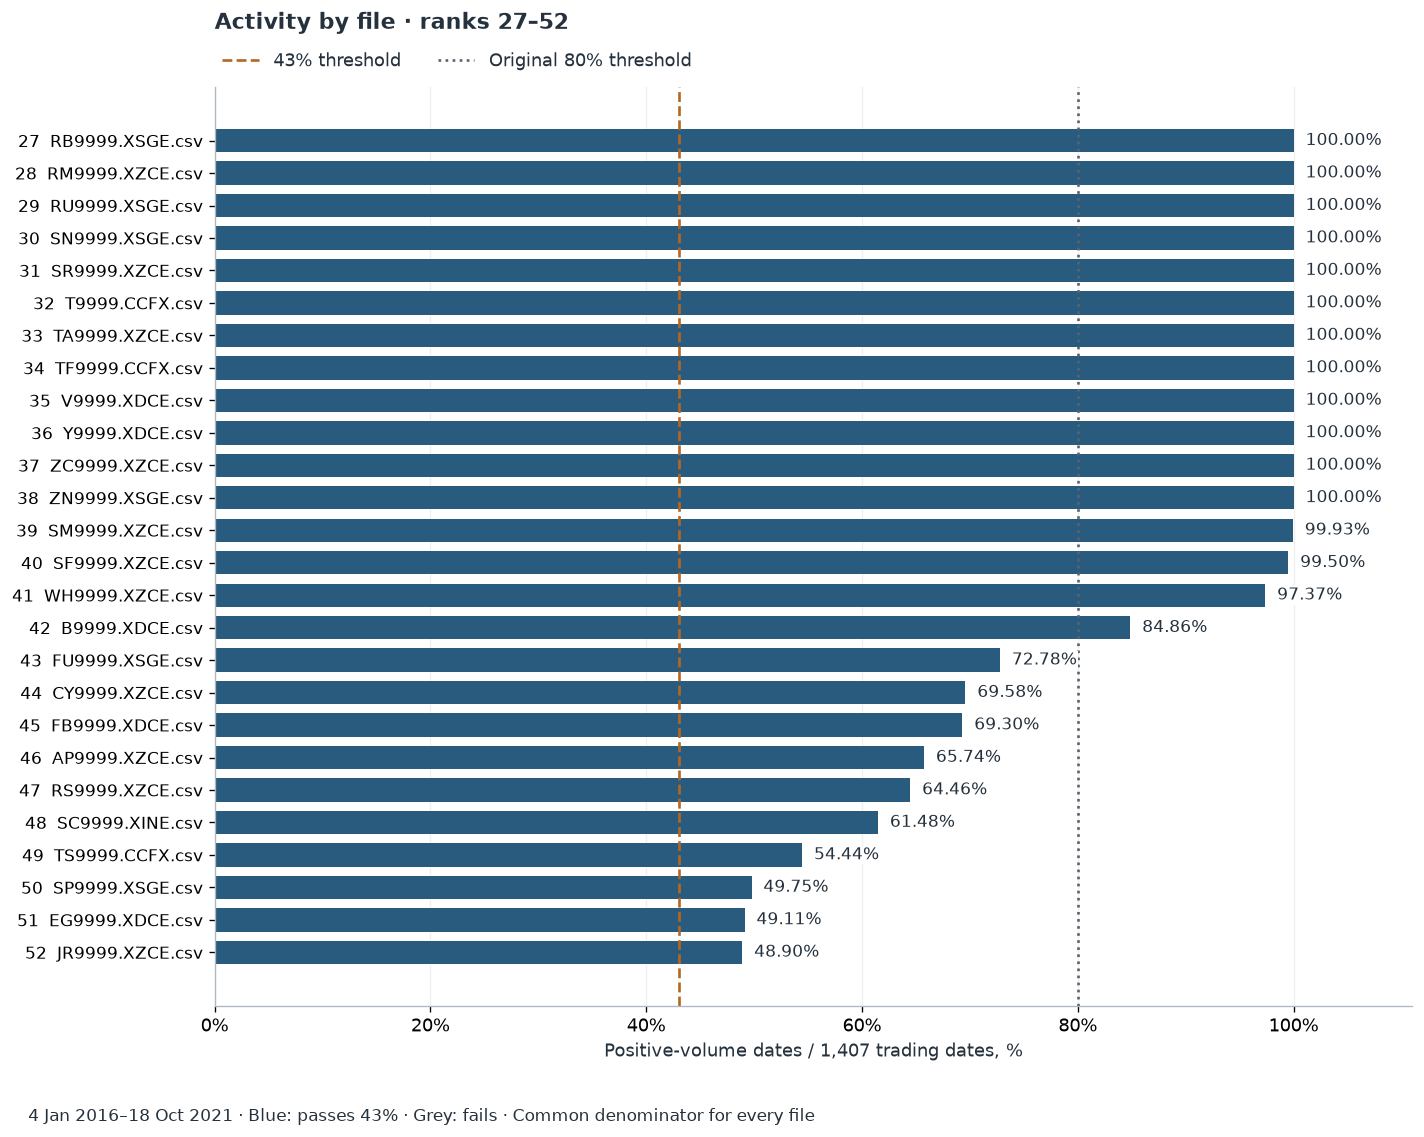

In [8]:
plot_file_activity(26, 52, "activity_by_file_27_52.png")

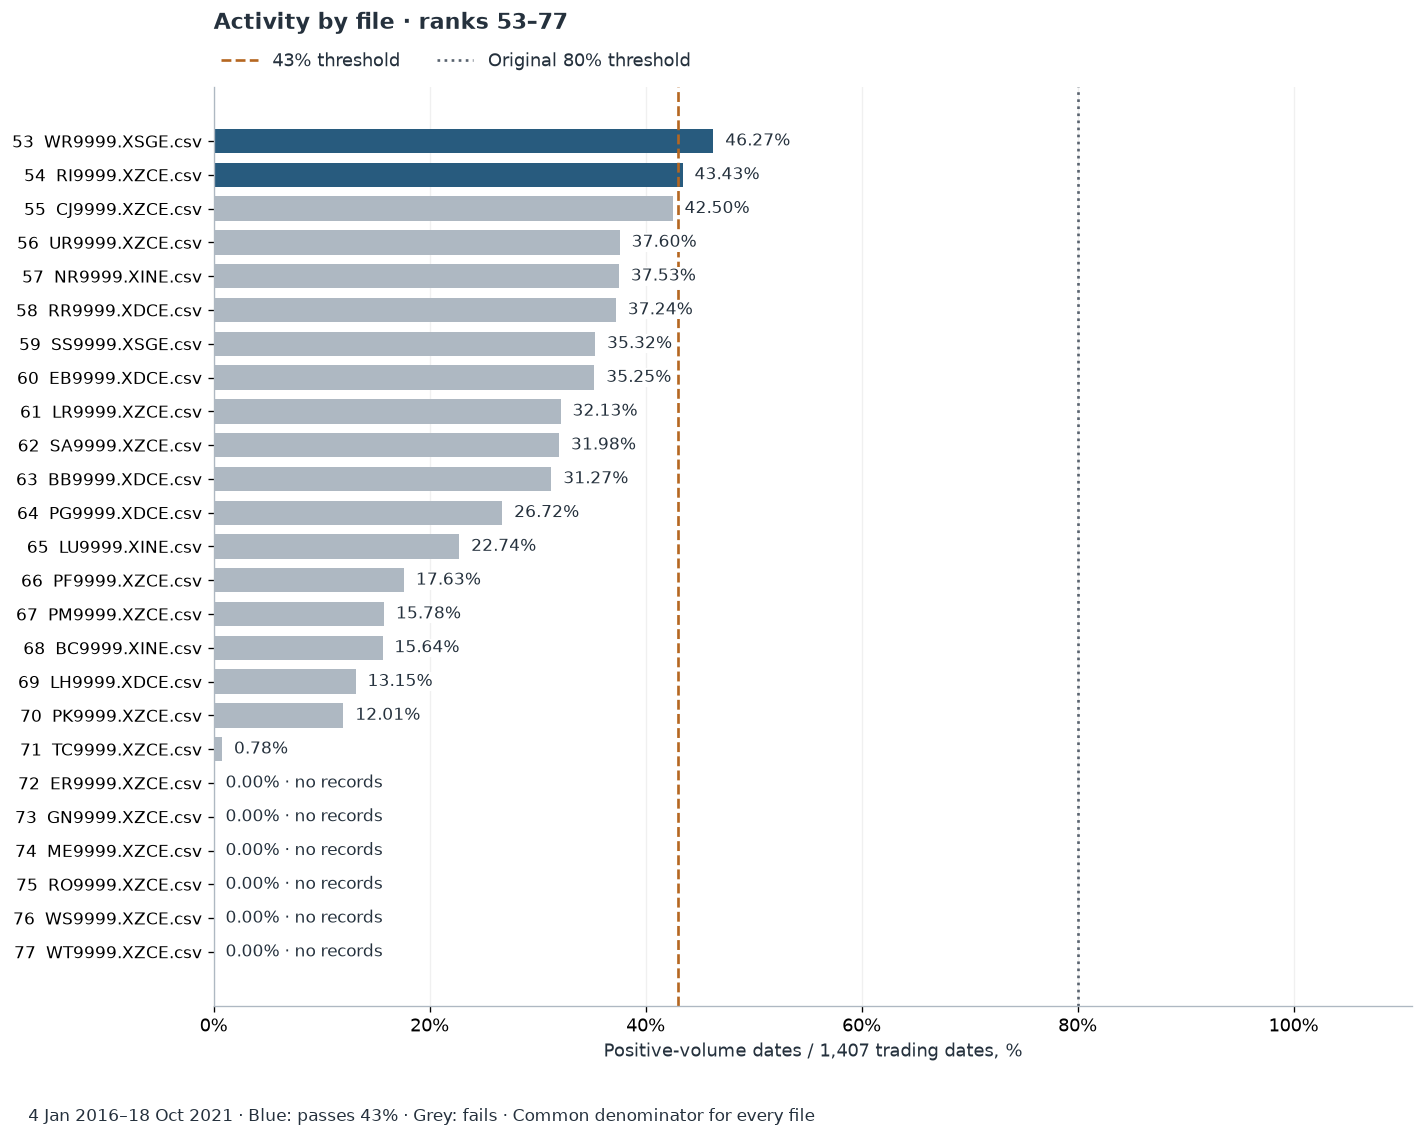

In [9]:
plot_file_activity(52, 77, "activity_by_file_53_77.png")

### 7. Full table and export

`activity_pct` uses the common 1,407-date denominator. The additional CSV field `own_days_activity_pct` divides by dates with records for that file and does not determine selection. A short history can therefore have 100% activity on its own observed dates and a low common-window share.


In [10]:
view = activity[["rank", "instrument", "positive_volume_days", "observed_days", "activity_pct", "passes_43pct"]].copy()
view.columns = ["Rank", "File", "Active dates", "Dates with records", "Activity, %", "43% selection"]
view["43% selection"] = view["43% selection"].map({True: "Pass", False: "Fail"})
show_table(view, {"Activity, %": "{:.4f}"}, scroll=True)

Rank,File,Active dates,Dates with records,"Activity, %",43% selection
1,A9999.XDCE.csv,1407,1407,100.0000,Pass
2,AG9999.XSGE.csv,1407,1407,100.0000,Pass
3,AL9999.XSGE.csv,1407,1407,100.0000,Pass
4,AU9999.XSGE.csv,1407,1407,100.0000,Pass
5,BU9999.XSGE.csv,1407,1407,100.0000,Pass
6,C9999.XDCE.csv,1407,1407,100.0000,Pass
7,CF9999.XZCE.csv,1407,1407,100.0000,Pass
8,CS9999.XDCE.csv,1407,1407,100.0000,Pass
9,CU9999.XSGE.csv,1407,1407,100.0000,Pass
10,FG9999.XZCE.csv,1407,1407,100.0000,Pass


### 8. Independent reconciliation and saved results


In [11]:
checks = []
# The daytime-only reference must match membership, not every date count.
daytime = window_sessions.loc[window_sessions.session.eq("daytime")].copy()
daytime_active = daytime.loc[daytime.positive_bars.gt(0)].groupby("instrument").trading_day.nunique().reindex(universe, fill_value=0)
for threshold, flag in [(SELECTED_THRESHOLD_PCT, "passes_43pct"), (BASELINE_THRESHOLD_PCT, "passes_80pct")]:
    daytime_selected = set(daytime_active.loc[daytime_active * 100 >= threshold * window_days].index)
    assert daytime_selected == set(activity.loc[activity[flag], "instrument"])
checks.append("Selection at 43% and 80% matches the independent daytime-only calculation.")
reference_days = pd.DatetimeIndex(daytime.loc[daytime.instrument.eq("IF9999.CCFX.csv"), "trading_day"].unique()).sort_values()
assert reference_days.equals(window_calendar)
checks.append("The common trading-date set matches the daytime dates of IF9999.CCFX.csv.")
previous_path = ROOT / "artifacts/research/liquidity_activity_2016_2021.csv"
if previous_path.exists():
    previous = pd.read_csv(previous_path).set_index("instrument").sort_index()
    current = activity.set_index("instrument").sort_index()
    columns = ["positive_volume_days", "observed_days", "window_trading_days", "activity_pct", "passes_80pct"]
    pd.testing.assert_frame_equal(current[columns], previous[columns], check_dtype=False)
    checks.append("Numerators, denominators, activity and 80% selection match the earlier calculation for every file.")

activity.to_csv(OUTPUT_DIR / "activity_by_file.csv", index=False, date_format="%Y-%m-%d")
activity.loc[activity.passes_43pct].to_csv(OUTPUT_DIR / "selected_54_files.csv", index=False, date_format="%Y-%m-%d")
calendar_table.to_csv(OUTPUT_DIR / "trading_calendar.csv", index=False, date_format="%Y-%m-%d")
calendar_by_year.to_csv(OUTPUT_DIR / "trading_days_by_year.csv", index=False)
threshold_results.to_csv(OUTPUT_DIR / "threshold_comparison.csv", index=False)
summary = {
    "requested_start": str(WINDOW_START.date()), "requested_end_inclusive": str((WINDOW_END_EXCLUSIVE - pd.Timedelta(days=1)).date()),
    "observed_first_trading_day": str(window_calendar.min().date()), "observed_last_trading_day": str(window_calendar.max().date()),
    "window_trading_days": window_days, "universe_files": len(activity),
    "files_with_observations": int(activity.has_observations.sum()),
    "files_without_observations": int((~activity.has_observations).sum()),
    "baseline_threshold_pct": BASELINE_THRESHOLD_PCT, "baseline_selected_files": int(activity.passes_80pct.sum()),
    "selected_threshold_pct": SELECTED_THRESHOLD_PCT, "selected_files": int(activity.passes_43pct.sum()),
    "target_selected_files": TARGET_FILES, "threshold_lower_exclusive_pct": lower_exclusive,
    "threshold_upper_inclusive_pct": upper_inclusive,
    "unknown_volume_bars": int(daily.unknown_volume_bars.sum()), "uncertain_activity_days": int(daily.uncertain_activity.sum()),
    "source": str(SOURCE.relative_to(ROOT)), "source_sha256": source_sha256,
    "calendar_method": "Empirical daytime dates; evening sessions map to next daytime date and early sessions to the first date on or after their timestamp date.",
    "coverage_caveat": "Source ends 2021-10-18; the rest of 2021 is not in the denominator. Missing instrument-days are not counted as positive-volume days.",
    "threshold_caveat": "43% was selected in-sample to obtain 54 files, not as an independent liquidity standard.",
    "calculated_at_utc": datetime.now(timezone.utc).isoformat(), "checks": checks,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "pyarrow": pa.__version__, "matplotlib": matplotlib.__version__},
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
for check in checks:
    print("✓", check)
print(f"Results: {OUTPUT_DIR.relative_to(ROOT)}")
print(f"Selected at 43%: {activity.passes_43pct.sum()} files. Excluded: {(~activity.passes_43pct).sum()}.")

✓ Selection at 43% and 80% matches the independent daytime-only calculation.
✓ The common trading-date set matches the daytime dates of IF9999.CCFX.csv.
✓ Numerators, denominators, activity and 80% selection match the earlier calculation for every file.
Results: artifacts/research/liquidity_activity
Selected at 43%: 54 files. Excluded: 23.


## Intermediate result: activity-only selection

- In the observed 2016–18 October 2021 window, 43% admits **54/77** files; 80% admits **42**.
- The denominator is **1,407 trading dates**. The respective minimum positive-volume counts are **606** and **1,126** dates.
- The boundary lies between **RI (43.4257%)** and **CJ (42.5018%)**.
- This statistic measures observed trading frequency and whole-window coverage. Short histories receive a lower score even if every date after listing has trades.
- The source does not cover the end of 2021.

Outputs: `activity_by_file.csv`, `selected_54_files.csv` and `summary.json` under `artifacts/research/liquidity_activity/`. This historical comparison is retained; the next section defines the final universe.


## Final 54-product selection

### 9. Rules and metric definitions

1. **Activity ≥30%**, using the same 1,407-date denominator: at least **423 active dates**.
2. **Zero-volume minutes ≤38%** of recorded bars with known nonnegative volume. Missing minutes are not inserted into either count.
3. **Problematic bars ≤0.1%**. A problematic bar contains missing, nonfinite or negative volume, turnover or open interest; unknown/nonpositive OHLC; inconsistent OHLC bounds; or a zero-volume/turnover contradiction. The union avoids double counting. These are explicit working thresholds, not a claim that every retained bar is correct.
4. All **54 eligible files** are retained. Mean daily monetary turnover determines order. Exact ties use higher mean daily volume, higher mean closing OI, lower zero-volume share and filename, without hidden weights.

| Metric | Definition |
|---|---|
| Mean daily volume | Mean daily volume sum, retaining observed dates with zero sums |
| Mean daily monetary turnover | Mean daily `money` sum; primary ranking measure |
| Median daily turnover | Sensitivity of the mean to extreme dates |
| Mean closing open interest | Mean OI at the last recorded minute of each trading date; OI is not summed over time |
| Mean minute volume/OI | Additional means over known valid minute observations |
| Zero-volume minutes, % | Recorded zero-volume bars / recorded valid-volume bars ×100 |
| Problematic bars, % | Union of the stated defects / all recorded bars ×100 |

Daily means use each product's observed dates, rather than assigning zero turnover before its history begins. A daily sum enters the mean only when every recorded minute of that field is valid. An unknown or ambiguous closing OI snapshot is omitted and its date is counted separately. The source Parquet is unchanged and missing values are not filled.

`money` retains the vendor's monetary scale. Common currency and accounting conventions are assumed, without complete exchange-specification certification. Contract volume and OI depend on contract size and are reported separately. OHLCV proxies do not establish spread or depth. Selection uses all of 2016–2021 and was not known at the beginning of the backtest.

At the former 30% zero-volume limit, only 52 files qualify. The 54th candidate by zero-volume share is **B (37.9372%)**: 38% is the smallest integer limit admitting 54 under the other fixed rules. The next candidate, **TS (44.1267%)**, remains excluded. This threshold was selected for universe size and is not an independent liquidity or quality standard.


In [12]:
FINAL_ACTIVITY_MIN_PCT = 30
MAX_ZERO_VOLUME_PCT = 38
MAX_BAD_BAR_PCT = 0.1
FINAL_UNIVERSE_SIZE = 54
FINAL_DIR = OUTPUT_DIR / "final_54"
FINAL_FIGURE_DIR = FINAL_DIR / "figures"
FINAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Minimum active dates: {math.ceil(FINAL_ACTIVITY_MIN_PCT * window_days / 100)}/{window_days}.")

Minimum active dates: 423/1407.


### 10. Daily metrics and source-bar quality


In [13]:
liquidity_parts = []
closing_parts = []
price_fields = ["open", "high", "low", "close"]
measure_fields = ["volume", "money", "open_interest"]
liquidity_columns = ["instrument", "ID", "date", "symbol", *price_fields, *measure_fields]
for batch in dataset.to_batches(columns=liquidity_columns, filter=scan_filter, batch_size=400_000):
    frame = batch.to_pandas()
    if frame.empty:
        continue
    day = frame.date.dt.normalize()
    hour = frame.date.dt.hour
    day_index = calendar.searchsorted(day, side="left")
    evening = hour.ge(18).to_numpy()
    day_index[evening] = calendar.searchsorted(day.loc[evening], side="right")
    assert (day_index < len(calendar)).all()
    frame["trading_day"] = calendar.take(day_index).to_numpy()
    frame = frame.loc[frame.trading_day.isin(window_calendar)].copy()
    if frame.empty:
        continue
    invalid = pd.Series(False, index=frame.index)
    for field in measure_fields:
        valid = np.isfinite(frame[field]) & frame[field].ge(0)
        frame[field + "_valid_count"] = valid.astype("int64")
        frame[field + "_valid_sum"] = frame[field].where(valid, 0.0)
        frame[field + "_unknown_count"] = (~np.isfinite(frame[field])).astype("int64")
        frame[field + "_negative_count"] = (np.isfinite(frame[field]) & frame[field].lt(0)).astype("int64")
        invalid |= ~valid
    valid_prices = np.isfinite(frame[price_fields]).all(axis=1) & frame[price_fields].gt(0).all(axis=1)
    valid_prices &= (frame.high.ge(frame.low) & frame.open.between(frame.low, frame.high)
                     & frame.close.between(frame.low, frame.high))
    inconsistent = ((frame.volume.eq(0) & frame.money.gt(0)) |
                    (frame.volume.gt(0) & frame.money.eq(0)))
    frame["bad_bars"] = (invalid | ~valid_prices | inconsistent).astype("int64")
    frame["price_bad_bars"] = (~valid_prices).astype("int64")
    frame["inconsistent_bars"] = inconsistent.astype("int64")
    frame["zero_volume_bars"] = frame.volume.eq(0).astype("int64")
    frame["positive_volume_bars"] = (np.isfinite(frame.volume) & frame.volume.gt(0)).astype("int64")
    keys = ["instrument", "trading_day"]
    sum_fields = [field + suffix for field in measure_fields
                  for suffix in ["_valid_count", "_valid_sum", "_unknown_count", "_negative_count"]]
    sum_fields += ["bad_bars", "price_bad_bars", "inconsistent_bars", "zero_volume_bars", "positive_volume_bars"]
    grouping = frame.groupby(keys, observed=True, sort=False)
    partial = grouping[sum_fields].sum()
    partial["bars"] = grouping.size()
    liquidity_parts.append(partial.reset_index())
    last_timestamp = grouping.date.transform("max")
    # Retain every final-minute row rather than choose an arbitrary tied contract.
    closing_parts.append(frame.loc[frame.date.eq(last_timestamp), keys + ["date", "symbol", "ID", "open_interest"]].copy())

liquidity_daily = pd.concat(liquidity_parts, ignore_index=True).groupby(
    ["instrument", "trading_day"], observed=True, sort=True
).sum(numeric_only=True)
closing_candidates = pd.concat(closing_parts, ignore_index=True)
last_timestamp = closing_candidates.groupby(["instrument", "trading_day"]).date.transform("max")
closing_candidates = closing_candidates.loc[closing_candidates.date.eq(last_timestamp)].copy()
closing_counts = closing_candidates.groupby(["instrument", "trading_day"]).size()
closing_candidates["close_oi"] = closing_candidates.open_interest.where(
    np.isfinite(closing_candidates.open_interest) & closing_candidates.open_interest.ge(0))
closing_oi = closing_candidates.groupby(["instrument", "trading_day"]).close_oi.first().where(closing_counts.eq(1))
liquidity_daily["closing_open_interest"] = closing_oi
liquidity_daily["closing_snapshot_rows"] = closing_counts
for field in ["volume", "money"]:
    # Complete daily sum: unknown or negative values are not replaced by zero.
    liquidity_daily["daily_" + field] = liquidity_daily[field + "_valid_sum"].where(
        liquidity_daily[field + "_valid_count"].eq(liquidity_daily.bars))
assert not liquidity_daily.index.duplicated().any()
assert liquidity_daily.bars.sum() == daily.bars.sum()
assert liquidity_daily.volume_negative_count.sum() == 0
observed_positive_days = liquidity_daily.positive_volume_bars.gt(0).groupby(level="instrument").sum()
pd.testing.assert_series_equal(
    observed_positive_days.reindex(universe, fill_value=0).astype("int64"),
    activity.set_index("instrument").positive_volume_days.reindex(universe).astype("int64"),
    check_names=False)
del liquidity_parts, closing_parts, frame, batch
print(f"Daily observations: {len(liquidity_daily):,}; minute bars: {int(liquidity_daily.bars.sum()):,}.")

Daily observations: 80,856; minute bars: 26,119,875.


### 11. Metrics for every source file


In [14]:
liquidity_metrics = liquidity_daily.groupby(level="instrument").agg(
    mean_daily_volume=("daily_volume", "mean"), median_daily_volume=("daily_volume", "median"),
    mean_daily_turnover=("daily_money", "mean"), median_daily_turnover=("daily_money", "median"),
    mean_closing_open_interest=("closing_open_interest", "mean"),
    valid_volume_days=("daily_volume", "count"), valid_turnover_days=("daily_money", "count"),
    valid_closing_oi_days=("closing_open_interest", "count"),
    bars=("bars", "sum"), zero_volume_bars=("zero_volume_bars", "sum"),
    bad_bars=("bad_bars", "sum"), price_bad_bars=("price_bad_bars", "sum"),
    inconsistent_bars=("inconsistent_bars", "sum"),
    known_volume_bars=("volume_valid_count", "sum"), volume_sum=("volume_valid_sum", "sum"),
    known_oi_bars=("open_interest_valid_count", "sum"), oi_sum=("open_interest_valid_sum", "sum"),
    volume_unknown_bars=("volume_unknown_count", "sum"), money_unknown_bars=("money_unknown_count", "sum"),
    oi_unknown_bars=("open_interest_unknown_count", "sum"),
    negative_money_bars=("money_negative_count", "sum"))
liquidity_metrics["mean_minute_volume"] = liquidity_metrics.volume_sum / liquidity_metrics.known_volume_bars
liquidity_metrics["mean_minute_open_interest"] = liquidity_metrics.oi_sum / liquidity_metrics.known_oi_bars
liquidity_metrics["zero_volume_pct"] = 100 * liquidity_metrics.zero_volume_bars / liquidity_metrics.known_volume_bars
liquidity_metrics["bad_bar_pct"] = 100 * liquidity_metrics.bad_bars / liquidity_metrics.bars
liquidity_metrics = activity[["instrument", "activity_pct", "positive_volume_days", "observed_days",
                              "window_trading_days", "first_day", "last_day", "has_observations"]].merge(
    liquidity_metrics.reset_index(), on="instrument", how="left", validate="one_to_one")
for field in ["volume", "turnover", "closing_oi"]:
    liquidity_metrics["excluded_" + field + "_days"] = liquidity_metrics.observed_days - liquidity_metrics["valid_" + field + "_days"]
liquidity_metrics["active_30pct"] = liquidity_metrics.positive_volume_days * 100 >= FINAL_ACTIVITY_MIN_PCT * window_days
liquidity_metrics["passes_zero_volume"] = liquidity_metrics.zero_volume_pct.le(MAX_ZERO_VOLUME_PCT)
liquidity_metrics["passes_quality"] = liquidity_metrics.bad_bar_pct.le(MAX_BAD_BAR_PCT)
liquidity_metrics["usable_ranking_metrics"] = (
    np.isfinite(liquidity_metrics[["mean_daily_volume", "mean_daily_turnover", "mean_closing_open_interest"]]).all(axis=1)
    & liquidity_metrics[["mean_daily_volume", "mean_daily_turnover", "mean_closing_open_interest"]].gt(0).all(axis=1))
liquidity_metrics["eligible_final"] = (liquidity_metrics.active_30pct & liquidity_metrics.passes_zero_volume
                                       & liquidity_metrics.passes_quality & liquidity_metrics.usable_ranking_metrics)
quality_totals = pd.DataFrame({
    "Check": ["Unknown volume", "Unknown turnover", "Unknown OI", "Negative turnover",
                 "Invalid/unknown OHLC", "Inconsistent volume and turnover", "Ambiguous closing OI"],
    "Count": [int(liquidity_metrics.volume_unknown_bars.sum()), int(liquidity_metrics.money_unknown_bars.sum()),
                  int(liquidity_metrics.oi_unknown_bars.sum()), int(liquidity_metrics.negative_money_bars.sum()),
                  int(liquidity_metrics.price_bad_bars.sum()), int(liquidity_metrics.inconsistent_bars.sum()),
                  int(liquidity_daily.closing_snapshot_rows.ne(1).sum())],
    "Unit": ["minute bars"] * 6 + ["trading dates"]})
show_table(quality_totals)

Check,Count,Unit
Unknown volume,25,minute bars
Unknown turnover,36,minute bars
Unknown OI,12,minute bars
Negative turnover,15,minute bars
Invalid/unknown OHLC,357,minute bars
Inconsistent volume and turnover,0,minute bars
Ambiguous closing OI,0,trading dates


### 12. Filters and final ranking


In [15]:
# Check the zero-volume boundary separately from the turnover ranking.
zero_limit_candidates = liquidity_metrics.loc[
    liquidity_metrics.active_30pct & liquidity_metrics.passes_quality & liquidity_metrics.usable_ranking_metrics
].sort_values(["zero_volume_pct", "instrument"]).reset_index(drop=True)
zero_lower_inclusive = float(zero_limit_candidates.iloc[FINAL_UNIVERSE_SIZE - 1].zero_volume_pct)
zero_upper_exclusive = float(zero_limit_candidates.iloc[FINAL_UNIVERSE_SIZE].zero_volume_pct)
assert zero_lower_inclusive <= MAX_ZERO_VOLUME_PCT < zero_upper_exclusive
print(f"Threshold interval for exactly {FINAL_UNIVERSE_SIZE} files: "
      f"[{zero_lower_inclusive:.8f}%; {zero_upper_exclusive:.8f}%). Selected {MAX_ZERO_VOLUME_PCT}%.")

rank_columns = ["mean_daily_turnover", "mean_daily_volume", "mean_closing_open_interest", "zero_volume_pct", "instrument"]
rank_ascending = [False, False, False, True, True]
liquidity_candidates = liquidity_metrics.loc[liquidity_metrics.eligible_final].sort_values(
    rank_columns, ascending=rank_ascending).reset_index(drop=True)
liquidity_candidates.insert(0, "liquidity_rank", np.arange(1, len(liquidity_candidates) + 1))
if len(liquidity_candidates) < FINAL_UNIVERSE_SIZE:
    raise ValueError(f"Only {len(liquidity_candidates)} files pass; the rules cannot be silently weakened.")
final_selected_assets = liquidity_candidates.head(FINAL_UNIVERSE_SIZE).copy()
final_universe = final_selected_assets.instrument.tolist()
liquidity_metrics = liquidity_metrics.merge(liquidity_candidates[["instrument", "liquidity_rank"]],
                                             on="instrument", how="left", validate="one_to_one")
liquidity_metrics["liquidity_rank"] = liquidity_metrics.liquidity_rank.astype("Int64")
liquidity_metrics["selected_final_54"] = liquidity_metrics.instrument.isin(final_universe)

def exclusion_reason(row):
    if row.selected_final_54:
        return "Selected"
    reasons = []
    if not row.has_observations: reasons.append("No observations in window")
    if not row.active_30pct: reasons.append("Activity <30%")
    if row.has_observations and not row.passes_zero_volume: reasons.append("Zero-volume minutes >38% or unavailable")
    if row.has_observations and not row.passes_quality: reasons.append("Problematic bars >0.1% or unavailable")
    if row.has_observations and not row.usable_ranking_metrics: reasons.append("Valid positive ranking metrics unavailable")
    if row.eligible_final: reasons.append("Turnover rank >54")
    return "; ".join(reasons)

liquidity_metrics["selection_reason"] = liquidity_metrics.apply(exclusion_reason, axis=1)
stages = pd.DataFrame({
    "Stage": ["All source files", "Activity ≥30%", "Also zero-volume minutes ≤38%",
             "Also problematic bars ≤0.1% and metrics available", "Final 54 ordered by turnover"],
    "Remaining files": [len(liquidity_metrics), int(liquidity_metrics.active_30pct.sum()),
                       int((liquidity_metrics.active_30pct & liquidity_metrics.passes_zero_volume).sum()),
                       len(liquidity_candidates), len(final_universe)]})
show_table(stages)

def readable_liquidity_table(frame):
    out = frame[["liquidity_rank", "instrument", "activity_pct", "mean_daily_turnover", "mean_daily_volume",
                 "mean_closing_open_interest", "zero_volume_pct", "bad_bar_pct"]].copy()
    out["mean_daily_turnover"] /= 1e9
    out.columns = ["Rank", "File", "Activity, %", "Turnover/date, billion units", "Volume/date", "Mean closing OI",
                   "Zero-volume minutes, %", "Problematic bars, %"]
    return out

liquidity_formats = {"Rank": "{:.0f}", "Activity, %": "{:.2f}", "Turnover/date, billion units": "{:.4f}",
                     "Volume/date": "{:,.0f}", "Mean closing OI": "{:,.0f}",
                     "Zero-volume minutes, %": "{:.3f}", "Problematic bars, %": "{:.4f}"}
show_table(readable_liquidity_table(liquidity_candidates.iloc[45:]), liquidity_formats)

Threshold interval for exactly 54 files: [37.93724233%; 44.12672901%). Selected 38%.


Stage,Remaining files
All source files,77
Activity ≥30%,63
Also zero-volume minutes ≤38%,54
Also problematic bars ≤0.1% and metrics available,54
Final 54 ordered by turnover,54


Rank,File,"Activity, %","Turnover/date, billion units",Volume/date,Mean closing OI,"Zero-volume minutes, %","Problematic bars, %"
46,CS9999.XDCE.csv,100.00,4.8632,"222,825","295,425",0.209,0.0005
47,SS9999.XSGE.csv,35.32,4.8478,"60,991","47,301",4.811,0.0132
48,SF9999.XZCE.csv,99.50,4.6590,"124,461","91,745",10.577,0.0000
49,PB9999.XSGE.csv,100.00,4.1568,"48,289","40,730",4.512,0.0037
50,UR9999.XZCE.csv,37.60,3.9546,"97,621","73,165",0.144,0.0017
51,B9999.XDCE.csv,84.86,1.7371,"50,756","58,875",37.937,0.0010
52,NR9999.XINE.csv,37.53,1.4896,"14,011","22,855",9.232,0.0110
53,CY9999.XZCE.csv,69.58,1.2895,"11,138","7,315",35.699,0.0079
54,RR9999.XDCE.csv,37.24,0.3697,"10,385","15,221",25.555,0.0047


### 13. Turnover and zero-volume minutes

Each point is a file with activity ≥30%. The vertical line marks the 38% zero-volume limit. Monetary turnover uses a logarithmic scale; blue points are the selected 54 and grey crosses fail the rules.


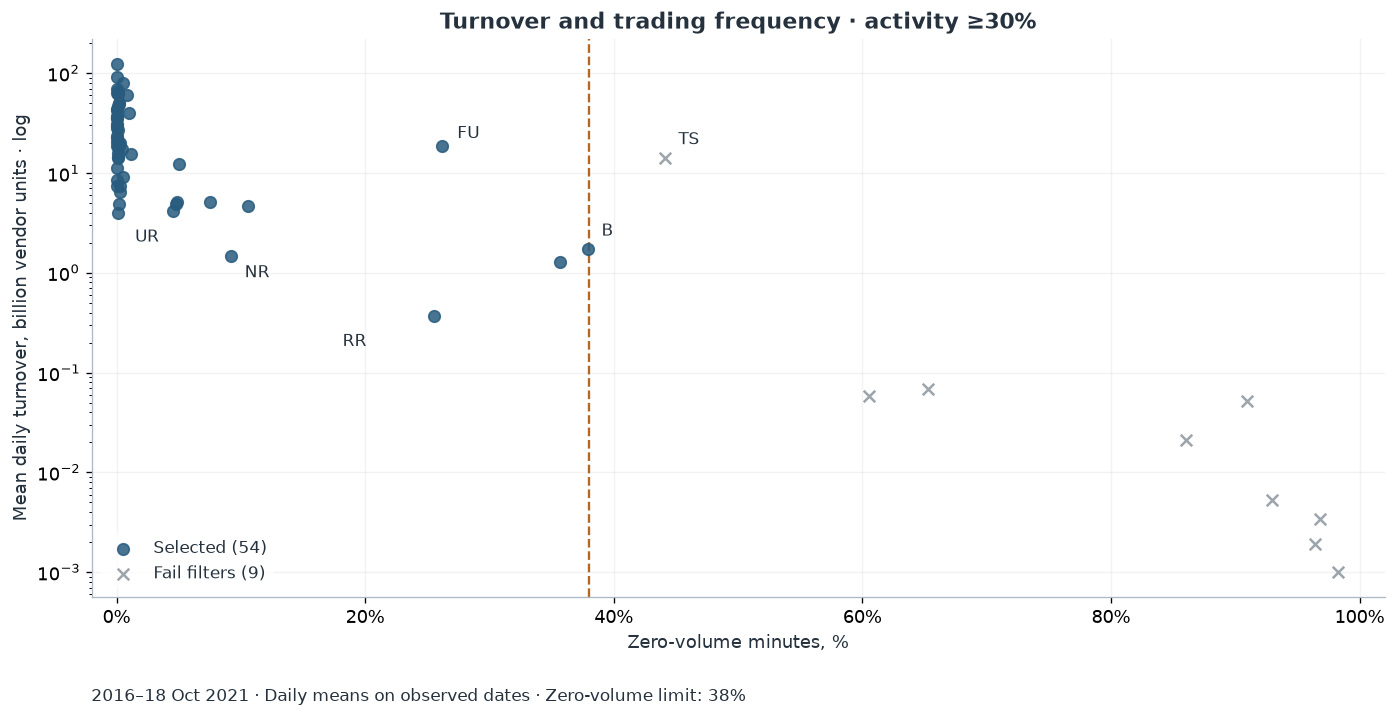

In [16]:
from matplotlib.lines import Line2D
active_view = liquidity_metrics.loc[liquidity_metrics.active_30pct].copy()
fig, ax = plt.subplots(figsize=(11.8, 6))
plot_groups = [
    (active_view.selected_final_54, COLORS["pass"], "o", "Selected"),
    (active_view.eligible_final & ~active_view.selected_final_54, COLORS["threshold"], "D", "Eligible, rank >54"),
    (~active_view.eligible_final, "#8B949E", "x", "Fail filters"),
]
for mask, color, marker, label in plot_groups:
    part = active_view.loc[mask]
    if part.empty:
        continue
    ax.scatter(part.zero_volume_pct, part.mean_daily_turnover / 1e9, c=color, marker=marker,
               s=48, alpha=0.85, label=f"{label} ({len(part)})", zorder=3)
ax.axvline(MAX_ZERO_VOLUME_PCT, color=COLORS["threshold"], linestyle="--", linewidth=1.4)
for name, offset in {"UR9999.XZCE.csv": (10, -17), "NR9999.XINE.csv": (8, -13),
                     "RR9999.XDCE.csv": (-55, -18), "FU9999.XSGE.csv": (9, 5),
                     "TS9999.CCFX.csv": (8, 8), "B9999.XDCE.csv": (8, 8)}.items():
    point = active_view.loc[active_view.instrument.eq(name)]
    if not point.empty:
        row = point.iloc[0]
        ax.annotate(name.split("9999")[0], (row.zero_volume_pct, row.mean_daily_turnover / 1e9),
                    xytext=offset, textcoords="offset points", fontsize=10)
ax.set(yscale="log", xlim=(-2, 102), xlabel="Zero-volume minutes, %",
       ylabel="Mean daily turnover, billion vendor units · log",
       title="Turnover and trading frequency · activity ≥30%")
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.grid(alpha=0.16); ax.set_axisbelow(True)
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none", fontsize=10)
fig.text(0.07, 0.015, "2016–18 Oct 2021 · Daily means on observed dates · Zero-volume limit: 38%", fontsize=10)
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(FINAL_FIGURE_DIR / "turnover_vs_zero_volume.png", dpi=160, bbox_inches="tight")
plt.show()

### 14. Final 54 products ranked by turnover

Two charts display every selected file on a common scale. Labels use billions of vendor monetary units. The following table retains the additional metrics.


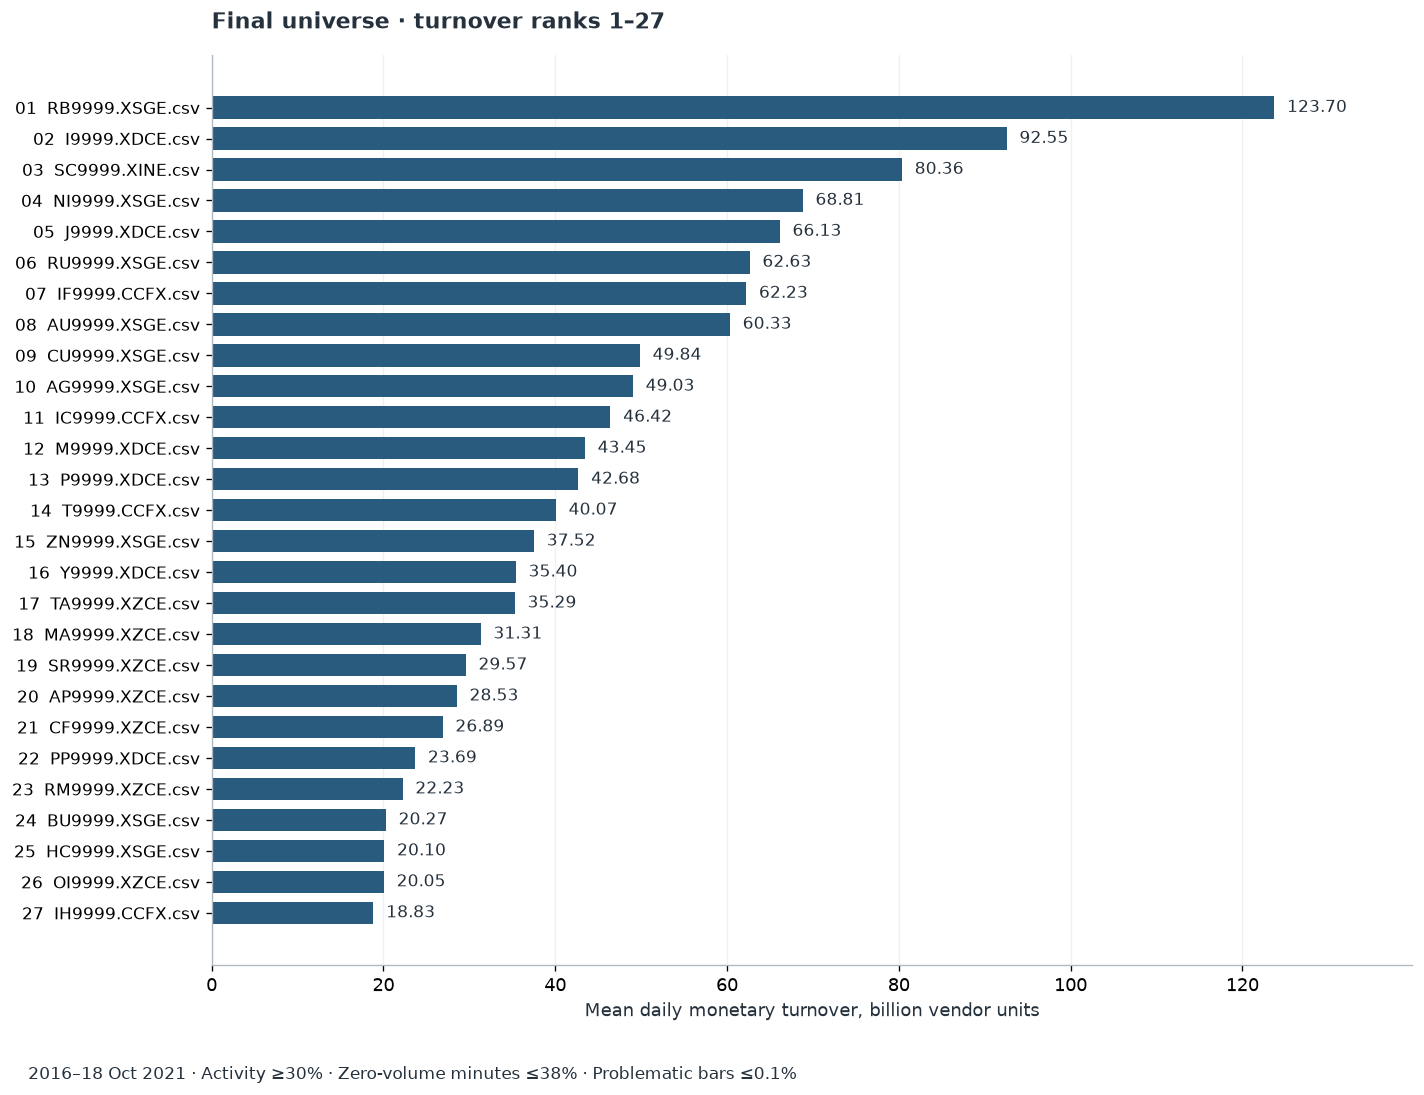

In [17]:
def plot_selected_turnover(start, stop, name):
    group = final_selected_assets.iloc[start:stop]
    values = group.mean_daily_turnover / 1e9
    fig, ax = plt.subplots(figsize=(12, 9.2))
    positions = np.arange(len(group))
    ax.barh(positions, values, color=COLORS["pass"], height=0.72)
    ax.set_yticks(positions, [f"{r.liquidity_rank:02d}  {r.instrument}" for r in group.itertuples()], fontsize=10)
    ax.invert_yaxis()
    max_value = final_selected_assets.mean_daily_turnover.max() / 1e9
    for y, value in zip(positions, values):
        ax.text(value + max_value * 0.012, y, f"{value:.2f}", va="center", fontsize=10)
    ax.set_xlim(0, max_value * 1.13)
    ax.set_xlabel("Mean daily monetary turnover, billion vendor units")
    ax.set_title(f"Final universe · turnover ranks {start + 1}–{min(stop, len(final_selected_assets))}", loc="left", pad=16)
    ax.grid(axis="x", alpha=0.18); ax.set_axisbelow(True)
    fig.text(0.025, 0.015, "2016–18 Oct 2021 · Activity ≥30% · Zero-volume minutes ≤38% · Problematic bars ≤0.1%", fontsize=10)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(FINAL_FIGURE_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()

plot_selected_turnover(0, 27, "selected_turnover_01_27.png")

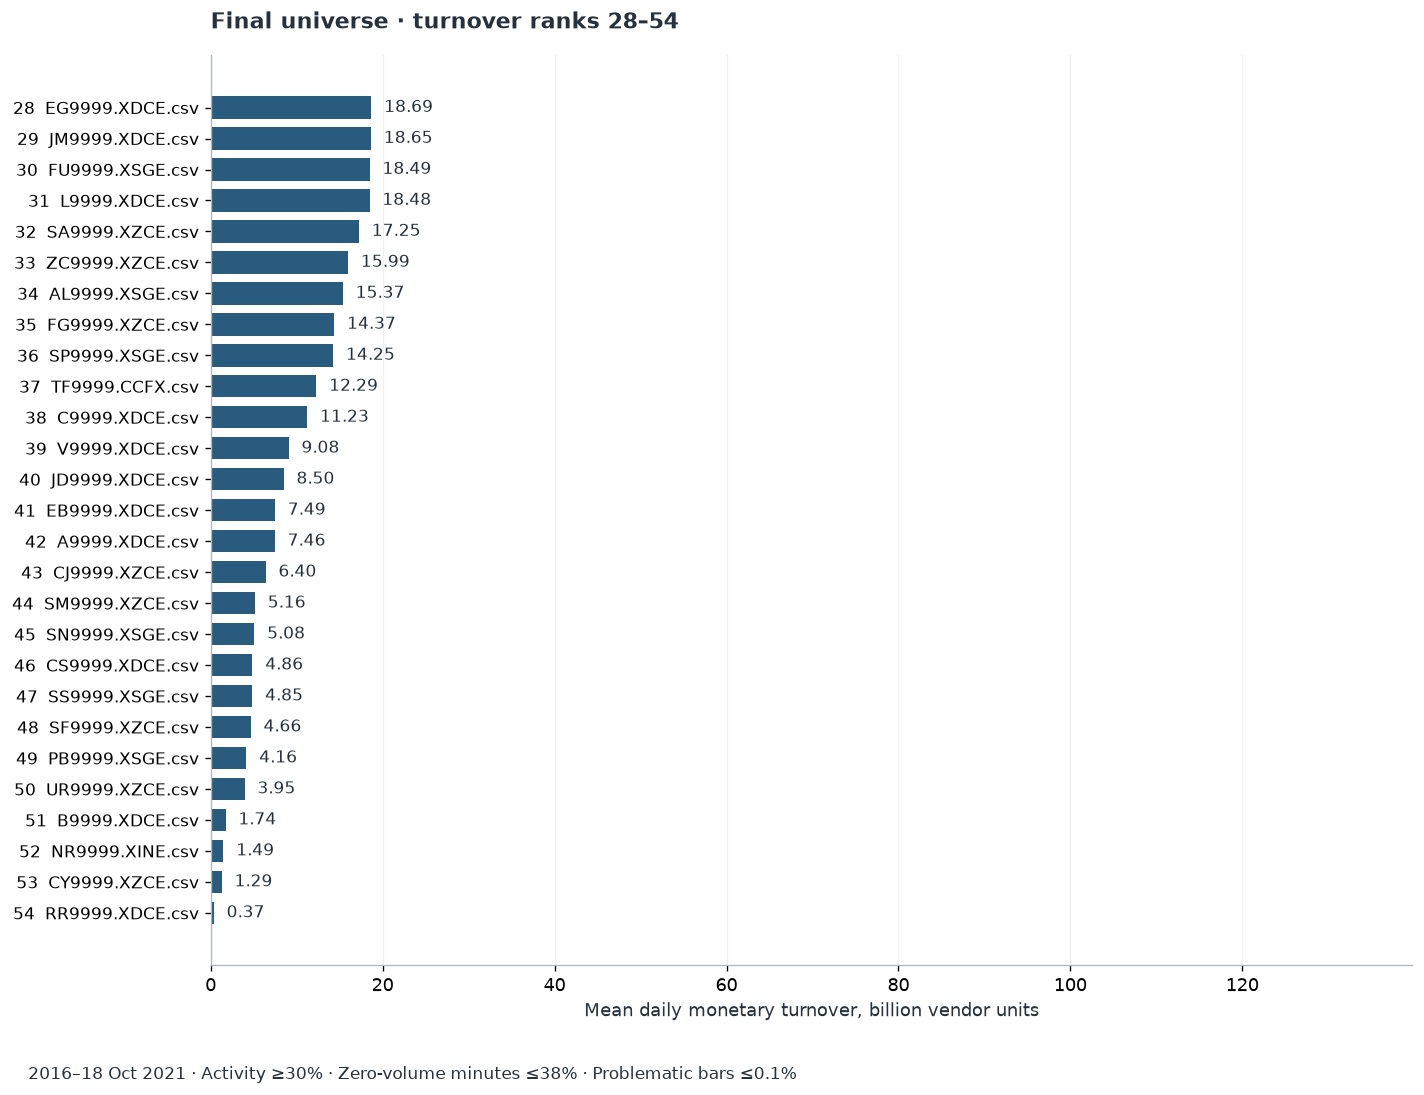

In [18]:
plot_selected_turnover(27, 54, "selected_turnover_28_54.png")

In [19]:
show_table(readable_liquidity_table(final_selected_assets), liquidity_formats, scroll=True)

Rank,File,"Activity, %","Turnover/date, billion units",Volume/date,Mean closing OI,"Zero-volume minutes, %","Problematic bars, %"
1,RB9999.XSGE.csv,100.00,123.6992,"3,706,716","2,273,909",0.041,0.0004
2,I9999.XDCE.csv,100.00,92.5536,"1,655,744","1,114,717",0.041,0.0002
3,SC9999.XINE.csv,61.48,80.3599,"188,643","35,479",0.534,0.0040
4,NI9999.XSGE.csv,100.00,68.8072,"665,472","318,363",0.049,0.0003
5,J9999.XDCE.csv,100.00,66.1310,"340,429","224,740",0.096,0.0006
6,RU9999.XSGE.csv,100.00,62.6301,"473,789","295,414",0.043,0.0002
7,IF9999.CCFX.csv,100.00,62.2268,"48,909","52,886",0.103,0.0000
8,AU9999.XSGE.csv,100.00,60.3328,"191,639","259,438",0.866,0.0029
9,CU9999.XSGE.csv,100.00,49.8417,"207,652","184,433",0.156,0.0008
10,AG9999.XSGE.csv,100.00,49.0326,"716,493","586,279",0.206,0.0008


### 15. Checks and authoritative downstream universe

Checks cover universe size, uniqueness, every filter, the admissible zero-volume threshold interval and turnover ordering. All 54 eligible candidates are included; there is no 55th eligible file. Changing the sorting statistic from mean to median cannot change membership in this case and is not a robustness test of selection.

Exports include all 77 files and inclusion/exclusion reasons, the 54-product table, trading-date metrics and a JSON containing `instruments`, dates, thresholds and source checksum. The authoritative input is **`final_universe` / `final_54/selected_54_universe.json`**. `final_50` and activity-only selection remain historical records.


In [20]:
assert len(final_universe) == FINAL_UNIVERSE_SIZE and len(set(final_universe)) == FINAL_UNIVERSE_SIZE
assert final_selected_assets.eligible_final.all()
assert final_selected_assets.activity_pct.ge(FINAL_ACTIVITY_MIN_PCT).all()
assert final_selected_assets.zero_volume_pct.le(MAX_ZERO_VOLUME_PCT).all()
assert final_selected_assets.bad_bar_pct.le(MAX_BAD_BAR_PCT).all()
assert final_selected_assets.mean_daily_turnover.is_monotonic_decreasing
if len(liquidity_candidates) > FINAL_UNIVERSE_SIZE:
    assert final_selected_assets.iloc[-1].mean_daily_turnover >= liquidity_candidates.iloc[FINAL_UNIVERSE_SIZE].mean_daily_turnover
else:
    assert set(final_universe) == set(liquidity_candidates.instrument)
assert int(liquidity_metrics.selected_final_54.sum()) == FINAL_UNIVERSE_SIZE
median_selected = set(liquidity_candidates.sort_values(["median_daily_turnover", "instrument"], ascending=[False, True])
                      .head(FINAL_UNIVERSE_SIZE).instrument)
median_overlap = len(median_selected & set(final_universe))
quality_selected = final_selected_assets[["bad_bars", "volume_unknown_bars", "money_unknown_bars",
                                          "oi_unknown_bars", "negative_money_bars"]].sum()
final_selected_assets["selected_final_54"] = True
liquidity_metrics.sort_values(["selected_final_54", "liquidity_rank", "instrument"], ascending=[False, True, True]).to_csv(
    FINAL_DIR / "all_files_liquidity_ranking.csv", index=False, date_format="%Y-%m-%d")
liquidity_candidates.to_csv(FINAL_DIR / "eligible_candidates.csv", index=False, date_format="%Y-%m-%d")
final_selected_assets.to_csv(FINAL_DIR / "selected_54_assets.csv", index=False, date_format="%Y-%m-%d")
stages.to_csv(FINAL_DIR / "selection_stages.csv", index=False)
liquidity_daily.reset_index().to_parquet(FINAL_DIR / "daily_liquidity_metrics.parquet", index=False)
final_manifest = {
    "universe_name": "active30_liquidity_top54_2016_2021", "instruments": final_universe,
    "source": str(SOURCE.relative_to(ROOT)), "source_sha256": source_sha256,
    "requested_start": str(WINDOW_START.date()),
    "requested_end_inclusive": str((WINDOW_END_EXCLUSIVE - pd.Timedelta(days=1)).date()),
    "observed_start": str(window_calendar.min().date()), "observed_end": str(window_calendar.max().date()),
    "window_trading_days": window_days, "activity_min_pct": FINAL_ACTIVITY_MIN_PCT,
    "zero_volume_max_pct": MAX_ZERO_VOLUME_PCT, "bad_bar_max_pct": MAX_BAD_BAR_PCT,
    "ranking": {"columns": rank_columns, "ascending": rank_ascending,
                "main_metric": "Mean daily money sum over observed trading days with complete valid money bars; zero days included."},
    "open_interest_definition": "Mean last-recorded-minute open interest per trading day; no summation across time.",
    "zero_volume_definition": "Registered bars with volume=0 divided by registered bars with finite nonnegative volume.",
    "quality_definition": "Union of missing/nonfinite/invalid OHLC, volume, money, open_interest and volume-money zero inconsistencies.",
    "universe_files": len(liquidity_metrics), "active_candidates": int(liquidity_metrics.active_30pct.sum()),
    "eligible_candidates": len(liquidity_candidates), "selected_files": len(final_universe),
    "mean_vs_median_selection_overlap": median_overlap,
    "mean_vs_median_selection_informative": len(liquidity_candidates) > FINAL_UNIVERSE_SIZE,
    "selection_limited_by_ranking": len(liquidity_candidates) > FINAL_UNIVERSE_SIZE,
    "zero_volume_limit_lower_inclusive_pct": zero_lower_inclusive,
    "zero_volume_limit_upper_exclusive_pct": zero_upper_exclusive,
    "threshold_status": "The zero-volume limit is 38%, the smallest whole percent yielding the requested 54 files. This is a sample-calibrated count constraint, not an independent liquidity standard; the 0.1% error limit is a working assumption.",
    "caveats": ["Source ends 2021-10-18; the rest of 2021 is unavailable.",
                "Retrospective full-window selection uses future information relative to early backtest dates.",
                "Common currency and monetary counting convention across instruments are assumed, not independently verified.",
                "Clean universe does not mean every source bar is error-free; original bars are unchanged.",
                "Minutes absent from the source are not measured by the zero-volume-bar fraction."],
    "selected_quality_counts": {key: int(value) for key, value in quality_selected.items()},
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}
final_universe_path = FINAL_DIR / "selected_54_universe.json"
final_universe_path.write_text(json.dumps(final_manifest, ensure_ascii=False, indent=2) + "\n")
# Downstream filter for minute bars of the selected 54 instruments.
research_dataset = ds.dataset(SOURCE, format="parquet")
research_scan_filter = (ds.field("instrument").isin(final_universe)
                        & (ds.field("date") >= WINDOW_START.to_pydatetime())
                        & (ds.field("date") < WINDOW_END_EXCLUSIVE.to_pydatetime()))
# Example: research_dataset.to_batches(filter=research_scan_filter, columns=[...]).
loaded_universe = json.loads(final_universe_path.read_text())
assert loaded_universe["instruments"] == final_universe
print(f"Final universe: {len(final_universe)} unique instruments.")
print(f"Activity ≥30%: {liquidity_metrics.active_30pct.sum()}; after every filter: {len(liquidity_candidates)}.")
if len(liquidity_candidates) > FINAL_UNIVERSE_SIZE:
    print(f"Mean/median turnover membership overlap: {median_overlap}/{FINAL_UNIVERSE_SIZE}.")
else:
    print("All 54 eligible candidates are included; mean turnover determines order. Changing the sort does not change membership.")
print(f"Maximum selected zero-volume share: {final_selected_assets.zero_volume_pct.max():.4f}%.")
print(f"Maximum selected problematic-bar share: {final_selected_assets.bad_bar_pct.max():.6f}%.")
print(f"Downstream universe: {final_universe_path.relative_to(ROOT)}")

Final universe: 54 unique instruments.
Activity ≥30%: 63; after every filter: 54.
All 54 eligible candidates are included; mean turnover determines order. Changing the sort does not change membership.
Maximum selected zero-volume share: 37.9372%.
Maximum selected problematic-bar share: 0.013154%.
Downstream universe: artifacts/research/liquidity_activity/final_54/selected_54_universe.json


In [21]:
last_selected_final = final_selected_assets.iloc[-1]
next_by_zero = zero_limit_candidates.iloc[FINAL_UNIVERSE_SIZE]
display(Markdown(
    f"### Notebook 04 result\n\n"
    f"**77 files → {int(liquidity_metrics.active_30pct.sum())} with activity ≥30% → "
    f"{len(liquidity_candidates)} passing all filters → {len(final_universe)} in the working universe.**\n\n"
    f"Zero-volume-minute limit: **{MAX_ZERO_VOLUME_PCT}%**; problematic bars: at most **{MAX_BAD_BAR_PCT}%**. "
    f"All eligible files are included. Mean daily monetary turnover determines order; "
    f"volume, OI and zero-volume shares remain in the table. Lowest turnover: "
    f"**{last_selected_final.instrument}** ({last_selected_final.mean_daily_turnover/1e9:.4f} billion units/date).\n\n"
    f"Next candidate by increasing zero-volume share: **{next_by_zero.instrument}** "
    f"({next_by_zero.zero_volume_pct:.4f}%), above the {MAX_ZERO_VOLUME_PCT}% limit.\n\n"
    f"Relative to the former 50, **B, CY, NR and RR** are added. "
    f"Downstream universe: `final_universe` / `selected_54_universe.json`.\n\n"
    f"[Final 54 table](artifacts/research/liquidity_activity/final_54/selected_54_assets.csv) · "
    f"[All files and exclusion reasons](artifacts/research/liquidity_activity/final_54/all_files_liquidity_ranking.csv) · "
    f"[Universe JSON](artifacts/research/liquidity_activity/final_54/selected_54_universe.json)"
))

### Notebook 04 result

**77 files → 63 with activity ≥30% → 54 passing all filters → 54 in the working universe.**

Zero-volume-minute limit: **38%**; problematic bars: at most **0.1%**. All eligible files are included. Mean daily monetary turnover determines order; volume, OI and zero-volume shares remain in the table. Lowest turnover: **RR9999.XDCE.csv** (0.3697 billion units/date).

Next candidate by increasing zero-volume share: **TS9999.CCFX.csv** (44.1267%), above the 38% limit.

Relative to the former 50, **B, CY, NR and RR** are added. Downstream universe: `final_universe` / `selected_54_universe.json`.

[Final 54 table](artifacts/research/liquidity_activity/final_54/selected_54_assets.csv) · [All files and exclusion reasons](artifacts/research/liquidity_activity/final_54/all_files_liquidity_ranking.csv) · [Universe JSON](artifacts/research/liquidity_activity/final_54/selected_54_universe.json)